In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.colors as mcolors
import argparse
from pathlib import Path
import numpy as np
import sys
import os
import json
import scipy.linalg as sla

In [2]:
import matplotlib
import seaborn as sns
from types import SimpleNamespace

In [3]:
store_plots = True

In [4]:
hw_file = "../hardware.json"
predir = "prod"

In [5]:
sns.set(style="whitegrid")

matplotlib.rcParams.update(
{
"pgf.preamble": (
r"\usepackage{amsmath} \usepackage{amsfonts} \newcommand{\Var}{\operatorname{\mathds{V}!ar}}"
),
"pgf.texsystem": "pdflatex",
"font.family": "serif",
"text.usetex": True,
"pgf.rcfonts": True,
"axes.titleweight": "bold", # Make titles bold
"axes.titlesize": 16, # Increase title size
"axes.labelsize": 16, # Increase label size
"xtick.labelsize": 14, # Increase x-tick label size
"ytick.labelsize": 14, # Increase y-tick label size
"legend.fontsize": 12, # Increase legend font size
}
)

matplotlib.rcParams["text.latex.preamble"] = (
r"\usepackage{amsmath} \usepackage{amsfonts} \newcommand{\Var}{\operatorname{\mathds{V}!ar}}"
)

plt.rcParams.update(matplotlib.rcParams)

In [6]:
# returns Flops in unit that freq is given in
def compute_PP(cores, freq, Vsize, floatsize, ILP_fac, FMA_fac, nodes=1):
    return cores * freq * (Vsize / floatsize) * ILP_fac * FMA_fac * nodes

def compute_PP_vs_n(data):
    # possible FLOPs over n
    PP_vs_n = np.zeros(len(data["qubits"]), dtype=np.float64)
    for idx, n in enumerate(data["qubits"]):
        PP_vs_n[idx] = compute_PP(cores=data["cores"][idx], 
                            freq=data["freq"][idx], 
                            Vsize=data["HW"]["max_Vsize"], 
                            floatsize=8, 
                            ILP_fac=data["HW"]["ILP_factor_FMA"],
                            FMA_fac=2,
                            nodes=data["num_ranks"][idx])
    return PP_vs_n

def lighten(color, amount=0.5):
    r, g, b = mcolors.to_rgb(color)
    return (
        r + (1 - r) * amount,
        g + (1 - g) * amount,
        b + (1 - b) * amount,
    )

def compute_est_rel_err(est_moments, z_sigma):
    corr_est_rel_err = ((est_moments > 0) & (est_moments - z_sigma > 0))
    corr_est_rel_err = corr_est_rel_err | ((est_moments < 0) & (est_moments + z_sigma < 0))

    est_rel_err = z_sigma / np.abs( est_moments - np.sign(est_moments) * z_sigma )
    est_rel_err[~corr_est_rel_err] = np.inf

    return est_rel_err

def bound_tsvd(A, b, T_std=None, n_keep=None):
    U, s, Vt = np.linalg.svd(A)
    if n_keep is None:
        # keep singular values above the estimated noise floor
        threshold = T_std if T_std else s[0] * 1e-10
        n_keep = np.sum(s > threshold)
    s_inv = np.zeros_like(s)
    s_inv[:n_keep] = 1.0 / s[:n_keep]
    x = Vt.T @ (s_inv * (U.T @ b))
    return b @ x

def get_krylov_bound(Tvals, nval, sym):

    Hankel=np.zeros((nval,nval))
    for k in range(nval):
        for l in range(nval):
            Hankel[k,l]=Tvals[k+l+1]
        
    bvec=np.zeros(nval)
    for k in range(nval):
        bvec[k]=Tvals[k]

    # doing it like this is really important for numerical stability
    # inverting the Hankel matrix suffers from severe instabilities otherwise
    # (for non-tiny order)

    if sym:
        return bound_tsvd(Hankel, bvec)
    else:
        x = np.linalg.solve(Hankel, bvec)
        return np.real(bvec @ x)

def load_data(args, data_dir):
    # read in data_dir/*.npz
    data = {}
    qubits = []
    for npz_file in sorted(Path(data_dir).glob("*.npz")):
        tmp = dict(np.load(npz_file))
        for key in tmp:
            if type(tmp[key]) == np.ndarray and tmp[key].shape == (1,):
                tmp[key] = tmp[key][0]
        assert tmp["num_qubits"] not in data, "Only one file per num_qubits allowed"
        data[tmp["num_qubits"]] = tmp
        qubits.append(tmp["num_qubits"])

    # assert same parameters
    for idx, num_qubits in enumerate(data):
        if idx == 0:
            n_star = data[num_qubits]["n_star"]
            order = data[num_qubits]["order"]
            num_meas = data[num_qubits]["num_meas"]
            num_runs = data[num_qubits]["num_runs"]
            num_data_points = data[num_qubits]["num_data_points"]
        with open(f"{data_dir}/frequencies", "r") as f:
            lines = f.read().splitlines()
        if lines[idx + 1] != '':
            data[num_qubits]["freq"] = float(lines[idx + 1])            
        else:
            data[num_qubits]["freq"] = 0            
        # assert n_star == data[num_qubits]["n_star"]
        # assert order == data[num_qubits]["order"]
        # assert num_meas == data[num_qubits]["num_meas"]
        # assert num_runs == data[num_qubits]["num_runs"]
        # assert num_data_points == data[num_qubits]["num_data_points"]

    min_qb = int(qubits[0])
    num_meas = int(data[min_qb]["num_meas"])
    num_runs = int(data[min_qb]["num_runs"])       
    num_data_points = int(data[min_qb]["num_data_points"])       

    return data, np.array(qubits, dtype=int), n_star, np.arange(0, order, dtype=int), num_meas, num_runs, num_data_points


def extract_data(args, in_data, qubits, n_star, orders, num_meas, num_runs, num_data_points, compute_DICI=True, sym=False):
    assert type(num_meas) == int
    assert type(num_runs) == int
    assert type(num_data_points) == int
    assert 2 * n_star - 1 == orders[-1]
    assert 2 * n_star == len(orders)

    len_qubits = len(qubits)
    len_orders = len(orders)

    data = {
        "qubits": qubits,
        "orders": orders,
        "n_star": n_star,
        "num_meas": num_meas,
        "num_runs": num_runs,
        "num_data_points": num_data_points,
    }

    # shape = (len_qubits, 1)
    data["QFI"] = np.zeros(len_qubits, dtype=float)
    data["RE"] = np.zeros(len_qubits, dtype=float)
    data["runtimes"] = np.zeros(len_qubits, dtype=float)
    data["runtimesDSC"] = np.zeros(len_qubits, dtype=float)
    data["runtimesDSC_all"] = np.zeros([len_qubits, num_runs], dtype=float)
    data["num_threads"] = np.zeros(len_qubits, dtype=int)
    data["num_ranks"] = np.ones(len_qubits, dtype=int)
    data["vector_width"] = np.zeros(len_qubits, dtype=int)
    data["rmMB"] = np.zeros(len_qubits, dtype=float)
    data["rsptMB"] = np.zeros(len_qubits, dtype=float)
    data["rfMF"] = np.zeros(len_qubits, dtype=float)
    data["rmtMB"] = np.zeros(len_qubits, dtype=float)
    data["AP"] = np.zeros(len_qubits, dtype=float)
    data["PP"] = np.zeros(len_qubits, dtype=float)
    data["freq"] = np.zeros(len_qubits, dtype=float)

    # shape = (len_qubits, len_orders)
    data["Tvals"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["est_Tvals"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["ERR"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["ERR_max"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["RE"] = np.zeros([len_qubits, n_star], dtype=float)
    data["RE_max"] = np.zeros([len_qubits, len_orders], dtype=float)

    # shape = (len_qubits, len_orders, num_runs)
    data["DICI"] = np.zeros([len_qubits, len_orders, num_runs], dtype=float)

    # shape = (len_qubits, len_orders, num_data_points)
    data["inter_tidx"] = np.zeros([len_qubits, num_data_points], dtype=int)
    data["est_inter_Tvals"] = np.zeros([len_qubits, len_orders, num_data_points], dtype=float)
    data["inter_ERR_in_sigma"] = np.zeros([len_qubits, len_orders, num_data_points], dtype=float)
    data["inter_RE"] = np.zeros([len_qubits, num_data_points], dtype=float)
    data["inter_QFI"] = np.zeros([len_qubits, num_data_points], dtype=float)

    data["krylov_bounds"] = np.zeros([len_qubits, n_star], dtype=float)
    data["krylov_bounds_RE"] = np.zeros([len_qubits, n_star], dtype=float)
    
    for idx, n in enumerate(qubits):
        data["running"] = True
        if in_data[n]["inter_tidx"][-1] == 0:
            data["running"] = False

        QFI = np.tile(in_data[n]["QFI"], num_runs)
        inter_QFI = np.tile(in_data[n]["QFI"], num_data_points)
        inter_QFI = np.tile(inter_QFI, num_runs).reshape(num_runs, num_data_points)
        est_Tvals = in_data[n]["est_Tvals"].reshape(num_runs, len_orders)
        krylov_bounds = np.zeros([num_runs, n_star], dtype=float)
        krylov_bounds_RE = np.zeros([num_runs, n_star], dtype=float)
        for run in range(num_runs):
            for n_star_idx in range(n_star):
                krylov_bounds[run, n_star_idx] = get_krylov_bound(est_Tvals[run], n_star_idx + 1, sym)
                krylov_bounds_RE[run, n_star_idx] = np.abs(krylov_bounds[run, n_star_idx] - in_data[n]["QFI"])/in_data[n]["QFI"]
        data["krylov_bounds"][idx] = np.median(krylov_bounds, axis=0)
        data["krylov_bounds_RE"][idx] = np.median(krylov_bounds_RE, axis=0)
        data["RE"][idx] = np.median(krylov_bounds_RE, axis=0)

        if data["running"]:
            est_inter_Tvals = in_data[n]["est_inter_Tvals"].reshape(num_runs, num_data_points, len_orders)
            inter_tidx = in_data[n]["inter_tidx"]
            # inter_stderrs = in_data[n]["est_inter_std_errs"].reshape(num_runs, num_data_points, len_orders)
            # inter_z_sigma = args.CI_fac * inter_stderrs
            # est_inter_rel_err = compute_est_rel_err(est_inter_Tvals, inter_z_sigma)
            est_inter_QFI = np.zeros([num_runs, num_data_points], dtype=float)
            for run in range(num_runs):
                for dpt in range(num_data_points):
                    est_inter_QFI[run, dpt] = get_krylov_bound(est_inter_Tvals[run, dpt], n_star, sym)

        DSC_only_runtime = np.median(in_data[n]["runtimesDSC"]) # nasty

        if data["running"]:
            inter_errs_signed = inter_QFI - est_inter_QFI
            inter_errs_signed[inter_errs_signed == 0] = np.nan
            inter_errs = np.abs(inter_errs_signed)
            inter_rel_errs = inter_errs/np.abs(inter_QFI)

        data["runtimes"][idx] = in_data[n]["runtime"]
        data["runtimesDSC"][idx] = DSC_only_runtime
        data["runtimesDSC_all"][idx] = in_data[n]["runtimesDSC"]
        data["num_threads"][idx] = in_data[n]["num_threads"]
        data["vector_width"][idx] = in_data[n]["vector_width"]
        data["rmMB"][idx] = in_data[n]["rmMB"] # required memory in MB
        data["rsptMB"][idx] = in_data[n]["rsptMB"] # required array data (wo cs data) in MB 
        data["rfMF"][idx] = in_data[n]["rfMF"] # performed flops
        data["rmtMB"][idx] = in_data[n]["rmtMB"] # idk
        data["freq"][idx] = in_data[n]["freq"] * 1000 # GHz

        data["QFI"][idx] = in_data[n]["QFI"]

        if data["running"]:
            data["inter_tidx"][idx] = np.copy(inter_tidx)
            data["inter_RE"][idx] = np.median(inter_rel_errs, axis=0)
            data["inter_QFI"][idx] = np.median(est_inter_QFI, axis=0)

    # add hw data
    with open(args.hw_file) as f:
        data["HW"] = json.load(f)[args.hardware]    

    if np.all(data["freq"] == 0):
        for idx, n in enumerate(qubits):      
            data["freq"][idx] = data["HW"]["freq"]  

    # used cores
    cores = data["num_threads"].copy()
    cores[cores > data["HW"]["cores"]] = data["HW"]["cores"]        
    data["cores"] = cores

    # peak performance in MFLOPs
    PP = compute_PP(cores=data["HW"]["cores"], 
                            freq=data["freq"], 
                            Vsize=data["HW"]["max_Vsize"], 
                            floatsize=args.floatsize, 
                            ILP_fac=data["HW"]["ILP_factor_FMA"],
                            FMA_fac=2,
                            nodes=max(data["num_ranks"]))       

    # compute achieved performance for each n
    if data["running"] == True:
        kmax = 2 * n_star + 1
        Ns = 2**np.array(data["qubits"])     
        AP = 14 * (n_star + 1) * Ns * data["num_meas"] * (kmax - 1 + data["qubits"]) * data["qubits"] * Ns \
            + 6 * (n_star + 1) * Ns * data["num_meas"] * (kmax - 1 + data["qubits"]) * Ns # total flops
        AP = AP / 1e6 # Mflops
        AP = AP / data["runtimesDSC"] # MFLOPs  

    else:
        kmax = 2 * n_star + 1
        Ns = 2**np.array(data["qubits"])     
        AP = 14 * Ns * data["num_meas"] * data["qubits"] * Ns \
            + 6 * Ns * data["num_meas"] * Ns # total flops
        AP = AP / 1e6 # Mflops
        AP = AP / data["runtimesDSC"] # MFLOPs
        
        # memory/ cache usage
        x = np.array(data["rsptMB"]).copy()
        SMT = data["num_threads"] > data["HW"]["cores"]
        x[SMT] = x[SMT] * 2

        data["pk_per_core"] = x / 2
        data["xy_per_core"] = x / 2
   
    data["AP"] = AP
    data["PP"] = PP          

    data["total_mem"] = data["rmMB"].copy()    

    return data

In [7]:
def get_data(data_dir, out_dir, state, hardware, version, sym=False):

    args = SimpleNamespace()

    args.data_dir = data_dir
    args.out_dir = out_dir
    args.state = state
    args.CI_perc = 95
    args.CI_fac = 1.960
    args.hw_file = hw_file
    args.hardware = hardware
    args.tol = 1
    args.julia = 0
    args.version = version
    args.floatsize = 8 # B
    args.strict_tol = args.tol / 10

    in_data, qubits, n_star, orders, num_meas, num_runs, num_data_points = load_data(args, args.data_dir)
    data = extract_data(args, in_data, qubits, n_star, orders, num_meas, num_runs, num_data_points, compute_DICI=(args.version.startswith("running")), sym=sym)
    data["colors"] = [x for x in mcolors.TABLEAU_COLORS.keys()]
    data["markers"] = ["o", "v", "p", "*", "s", "X"]
    data["linestyles"] = ["-", ":", "-."]
    data["lw"] = 1

    return data

qubits = 8:  num_meas =  3000000, n* = 21, order = 43, num_runs = 11
prod/plots/QFI/RE_QFI


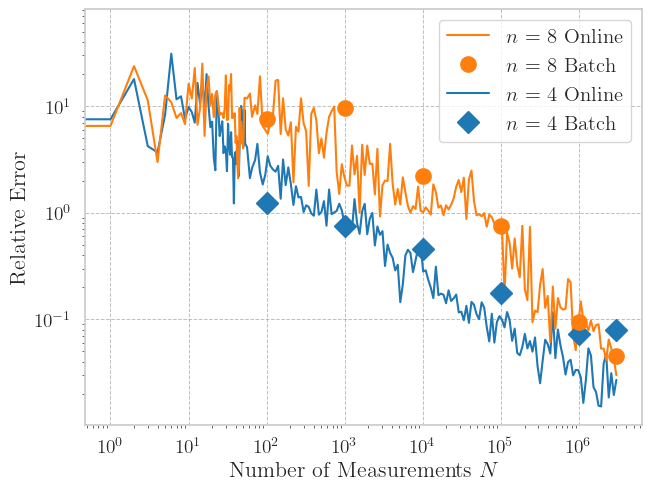

In [8]:
# rel errr

outdir = f"{predir}/plots"
outfile = f"{outdir}/QFI/RE_QFI"

ns = [4, 8]
ranks = [6]

num_batches = [2, 3, 4, 5, 6, 7]

svd = False

##################################################################

datas = {}

for rank in ranks:
    datas[rank] = get_data(f"{predir}/QFI/rank{rank}/running", outdir, "rankX", "9354P", "running", svd)

datas_batched = {}
for rank in ranks:
    datas_batched[rank] = []
    for x in num_batches:
        datas_batched[rank].append(get_data(f"{predir}/QFI/rank{rank}/batched_1e{x}", outdir, "rankX", "9354P", "batched", svd))

##################################################################

inter_tidx = {}
REs = {}

tidx_batched = {}
REs_batched = {}

for n in ns:
    nidx = np.where(datas[ranks[0]]["qubits"] == n)[0][0]
    inter_tidx[n] = {}
    REs[n] = {}
    for rank in ranks:
        inter_tidx[n][rank] = datas[rank]["inter_tidx"][nidx]
        REs[n][rank] = datas[rank]["inter_RE"][nidx]

        tidx_batched[n] = {}
        REs_batched[n] = {}
        tidx_batched[n][rank] = []
        REs_batched[n][rank] = []        
        for data in datas_batched[rank]:
            tidx_batched[n][rank].append(data["num_meas"])
            REs_batched[n][rank].append(data["RE"][nidx, -1])

##################################################################

fg, ax = plt.subplots(layout="constrained")

colors = [x for x in mcolors.TABLEAU_COLORS.keys()]
markers = ["D", "o", "*", "s", "X"]

for nidx, n in enumerate(ns):
    for idx, rank in enumerate(ranks):
        marker = markers[(nidx + idx)%len(markers)]
        c = colors[(nidx + idx)%len(colors)]
        ax.loglog(inter_tidx[n][rank], REs[n][rank], label=f"$n$ = {n} Online", c=c, markersize=12)

for nidx, n in enumerate(ns):
    for idx, rank in enumerate(ranks):
        marker = markers[(nidx + idx)%len(markers)]
        c = colors[(nidx + idx)%len(colors)]
        ax.loglog(tidx_batched[n][rank], REs_batched[n][rank], label=f"$n$ = {n} Batch", linestyle="none", marker=marker, c=c, markersize=11)


handles, labels = ax.get_legend_handles_labels()
handles = [handles[1], handles[3], handles[0], handles[2]]
labels = [labels[1], labels[3], labels[0], labels[2]]
ax.legend(handles, labels, ncol=1, fontsize=15, markerscale=1.0, handlelength=2.0)
ax.set_xlabel("Number of Measurements $N$")
ax.set_ylabel("Relative Error")
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)


ax.tick_params(
    axis="both",
    which="minor",
    bottom=True,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

for rank in ranks:
    data = datas[rank]
    print(f"qubits = {n}:  num_meas =  {data['num_meas']}, n* = {data['n_star']}, order = {int(2 * data['n_star'] + 1)}, num_runs = {data['num_runs']}")

if store_plots:
    # fg.savefig(f"{outfile}.png")
    print(outfile)
    fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
plt.show()

qubits = 8:  num_meas =  3000000, order = 7, num_runs = 11
qubits = 8:  num_meas =  3000000, order = 21, num_runs = 11
qubits = 8:  num_meas =  3000000, order = 43, num_runs = 11


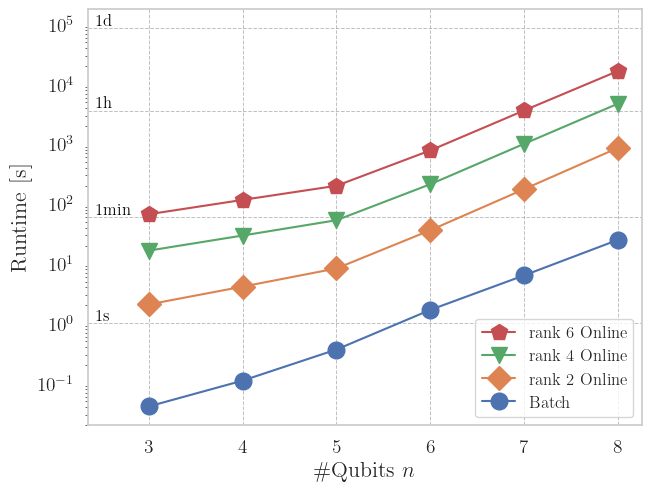

In [9]:
# rel errr

outdir = f"{predir}/plots"
outfile = f"{outdir}/QFI/runtimes_QFI"

n = 8
ranks = [2, 4, 6]

num_batches = [2, 3, 4, 5, 6, 7]

##################################################################

datas = {}

for rank in ranks:
    datas[rank] = get_data(f"{predir}/QFI/rank{rank}/running", outdir, "rankX", "9354P", "running")

datas_batched = {}
for rank in ranks:
    datas_batched[rank] = []
    for x in num_batches:
        datas_batched[rank].append(get_data(f"{predir}/QFI/rank{rank}/batched_1e{x}", outdir, "rankX", "9354P", "batched", svd))

##################################################################

qubits = datas[ranks[0]]["qubits"]

runtimes = {}
runtimes_batched = []

for rank in ranks:
    runtimes[rank] = datas[rank]["runtimes"]
    if rank == max(ranks):
        runtimes_batched = datas_batched[rank][-1]["runtimes"]


##################################################################

fg, ax = plt.subplots(layout="constrained")

colors = []
for i in range(10):
    colors.append(ax._get_lines.get_next_color())

markers = ["o", "D", "v", "p", "*", "s", "X"]


ax.axhline(y=1, linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.axhline(y=60, linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.axhline(y=60*60, linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.axhline(y=60*60*24, linestyle="--", linewidth=0.7, color="gray", alpha=0.5)

marker = markers[0%len(markers)]
c = colors[0%len(colors)]
ax.semilogy(qubits, runtimes_batched, marker=marker, label=f"Batch", c=c, markersize=12)

for idx, rank in enumerate(ranks):
    marker = markers[(idx+1)%len(markers)]
    c = colors[(idx+1)%len(colors)]
    ax.semilogy(qubits, runtimes[rank], marker=marker, label=f"rank {rank} Online", c=c, markersize=12)


handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], ncol=1, fontsize=12, markerscale=1.0, handlelength=2.0)
ax.set_xlabel("\#Qubits $n$")
ax.set_ylabel("Runtime [s]")
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)
ax.grid(axis="y", visible=False)

ax.set_xlim(2.35, None)      

ax.tick_params(
    axis="both",
    which="minor",
    bottom=False,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

ax.text(
    2.44, 1 * 1.125,
    "1s",
    color="black",
    fontsize=12
)

ax.text(
    2.44, 60 * 1.125,
    "1min",
    color="black",
    fontsize=12
)

ax.text(
    2.44, 60 * 60 * 1.125,
    "1h",
    color="black",
    fontsize=12
)

ax.text(
    2.44, 60 * 60 * 24 * 1.125,
    "1d",
    color="black",
    fontsize=12
)

for rank in ranks:
    data = datas[rank]
    print(f"qubits = {n}:  num_meas =  {data['num_meas']}, order = {int(2 * data['n_star'] + 1)}, num_runs = {data['num_runs']}")

if store_plots:
    # fg.savefig(f"{outfile}.png")
    fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
plt.show()